Create notebooks/04_bad_review.ipynb. The target is bad_review (review score of 1 or 2) on delivered orders. Model A uses only what is known at order time. Model B adds delivery outcomes.

In [ ]:
#Build the dataset
import sys
sys.path.append("..")
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier


region_map = {
    **dict.fromkeys(["AC","AP","AM","PA","RO","RR","TO"], "north"),
    **dict.fromkeys(["AL","BA","CE","MA","PB","PE","PI","RN","SE"], "northeast"),
    **dict.fromkeys(["DF","GO","MT","MS"], "center_west"),
    **dict.fromkeys(["ES","MG","RJ","SP"], "southeast"),
    **dict.fromkeys(["PR","RS","SC"], "south"),
}

df = pd.read_pickle("../data/orders_clean.pkl")
d = df[(df["order_status"] == "delivered") & df["review_score"].notna()].copy()

d["bad_review"]      = (d["review_score"] <= 2).astype(int)
d["region"]          = d["state"].map(region_map)
d["planned_days"]    = (d["estimated_ts"] - d["purchase_ts"]).dt.total_seconds() / 86400
d["days_early"]      = (d["estimated_ts"] - d["delivered_ts"]).dt.total_seconds() / 86400
d["approval_hours"]  = (d["approved_ts"] - d["purchase_ts"]).dt.total_seconds() / 3600
d["freight_ratio"]   = d["freight_value"] / d["items_value"].replace(0, np.nan)
d["log_items_value"] = np.log1p(d["items_value"])
d["purchase_month"]  = d["purchase_ts"].dt.month
d["purchase_dow"]    = d["purchase_ts"].dt.day_of_week
d["black_friday"]    = d["purchase_ts"].between("2017-11-23", "2017-11-27").astype(int)

top = d["main_category"].value_counts().head(20).index
d["category"] = d["main_category"].where(d["main_category"].isin(top), "other")

print(d.shape, "| bad review rate:", round(d["bad_review"].mean(), 4))

(95568, 38) | bad review rate: 0.1276


In [2]:
#Define the two feature sets
cat_cols = ["payment_type", "region", "category"]
order_time_num = ["log_items_value", "freight_value", "freight_ratio", "n_items", "n_sellers",
                  "avg_weight_g", "avg_photos", "avg_desc_len", "installments", "n_payments",
                  "used_voucher", "planned_days", "approval_hours", "purchase_month",
                  "purchase_dow", "black_friday"]
delivery_num = ["delivery_days", "is_late", "days_early"]

y = d["bad_review"]

In [3]:
#Compare models A and B with cross-validation
def make_pre(num_cols):
    num = Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)),
                    ("sc", StandardScaler())])
    cat = Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="missing")),
                    ("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
    return ColumnTransformer([("num", num, num_cols), ("cat", cat, cat_cols)])

clfs = {
    "logreg": LogisticRegression(max_iter=3000, class_weight="balanced", C=0.1),
    "hist_gb": HistGradientBoostingClassifier(max_depth=4, learning_rate=0.05, max_iter=250,
                                              min_samples_leaf=50, l2_regularization=1.0,
                                              random_state=42),
}
feature_sets = {"A_order_time": order_time_num,
                "B_plus_delivery": order_time_num + delivery_num}

cv = StratifiedKFold(5, shuffle=True, random_state=42)
rows = []
for fs_name, nums in feature_sets.items():
    X = d[nums + cat_cols]
    for name, clf in clfs.items():
        pipe = Pipeline([("pre", make_pre(nums)), ("clf", clf)])
        r = cross_validate(pipe, X, y, cv=cv,
                           scoring={"roc_auc": "roc_auc", "pr_auc": "average_precision"})
        rows.append({"features": fs_name, "model": name,
                     "roc_auc": r["test_roc_auc"].mean(), "pr_auc": r["test_pr_auc"].mean()})
pd.DataFrame(rows).round(4)

,features,model,roc_auc,pr_auc
0,A_order_time,logreg,0.6187,0.2166
1,A_order_time,hist_gb,0.6522,0.2444
2,B_plus_delivery,logreg,0.7512,0.4208
3,B_plus_delivery,hist_gb,0.7592,0.4767


In [4]:
#Train/test split and final scores for model B
import joblib
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.inspection import permutation_importance

nums = order_time_num + delivery_num
X = d[nums + cat_cols]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

model_b = Pipeline([("pre", make_pre(nums)), ("clf", clfs["hist_gb"])]).fit(X_tr, y_tr)
p = model_b.predict_proba(X_te)[:, 1]
print("Test ROC-AUC:", round(roc_auc_score(y_te, p), 4))
print("Test PR-AUC :", round(average_precision_score(y_te, p), 4), "| base rate:", round(y_te.mean(), 4))

Test ROC-AUC: 0.7619
Test PR-AUC : 0.4966 | base rate: 0.1276


In [5]:
#Lift by decile
res = pd.DataFrame({"y": y_te.values, "p": p})
res["decile"] = pd.qcut(res["p"].rank(method="first", ascending=False), 10, labels=range(1, 11))
lift = res.groupby("decile", observed=True)["y"].agg(orders="size", bad="sum", rate="mean")
lift["lift"] = lift["rate"] / res["y"].mean()
lift["cum_capture"] = lift["bad"].cumsum() / lift["bad"].sum()
lift.round(3)

,orders,bad,rate,lift,cum_capture
decile,,,,,
1,1912,1065,0.557,4.365,0.437
2,1911,314,0.164,1.288,0.565
3,1911,189,0.099,0.775,0.643
4,1912,168,0.088,0.689,0.712
5,1911,157,0.082,0.644,0.776
6,1911,132,0.069,0.541,0.830
7,1912,113,0.059,0.463,0.877
8,1911,114,0.060,0.468,0.923
9,1911,97,0.051,0.398,0.963


In [6]:
#What drives bad reviews
sub = X_te.sample(6000, random_state=42)
pi = permutation_importance(model_b, sub, y_te.loc[sub.index], scoring="roc_auc",
                            n_repeats=5, random_state=42, n_jobs=1)
imp = pd.Series(pi.importances_mean, index=X_te.columns).sort_values(ascending=False)
imp.head(12).round(4)

n_items           0.0612
days_early        0.0424
delivery_days     0.0406
category          0.0084
n_sellers         0.0023
avg_photos        0.0020
region            0.0018
planned_days      0.0015
freight_value     0.0014
installments      0.0011
avg_weight_g      0.0009
approval_hours    0.0008
dtype: float64

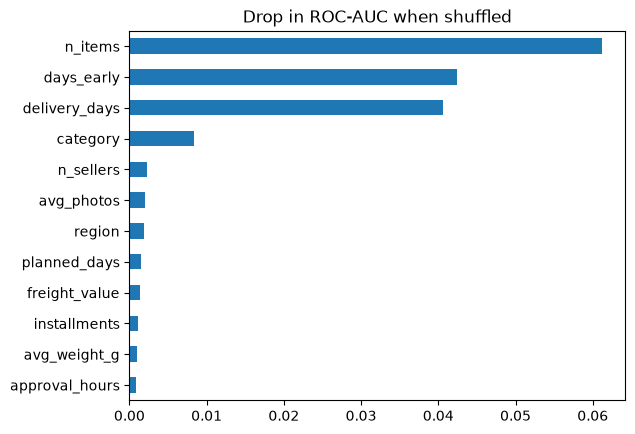

In [7]:
import matplotlib.pyplot as plt
imp.head(12).iloc[::-1].plot.barh(title="Drop in ROC-AUC when shuffled")
plt.show()

              orders  bad_rate
delay_bucket                  
10+ early      56652     0.089
5–10 early     22437     0.091
0–5 early       8813     0.110
0–5 late        3567     0.280
5–10 late       1861     0.738
10+ late        2230     0.791


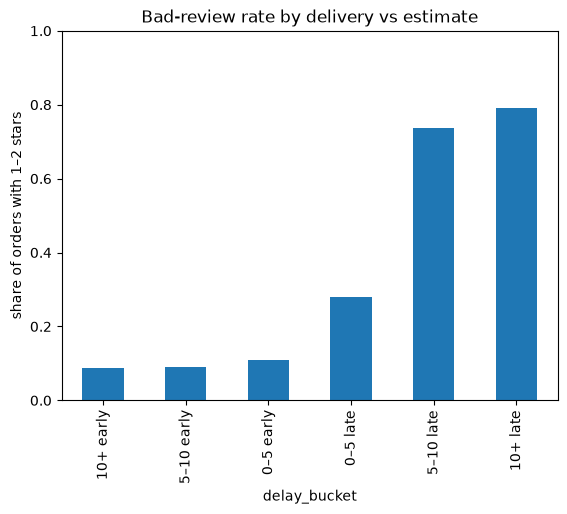

In [8]:
#Bad-review rate vs delivery vs estimate (a chart for your report)
d["days_vs_estimate"] = -d["days_early"]   # positive = late
d["delay_bucket"] = pd.cut(d["days_vs_estimate"], [-200, -10, -5, 0, 5, 10, 200],
                           labels=["10+ early", "5–10 early", "0–5 early",
                                   "0–5 late", "5–10 late", "10+ late"])
tbl = d.groupby("delay_bucket", observed=True)["bad_review"].agg(orders="size", bad_rate="mean")
print(tbl.round(3))
tbl["bad_rate"].plot.bar(title="Bad-review rate by delivery vs estimate", ylim=(0, 1))
plt.ylabel("share of orders with 1–2 stars"); plt.show()

In [9]:
Path("../artifacts").mkdir(exist_ok=True)
joblib.dump({"model": model_b, "features": nums + cat_cols},
            "../artifacts/bad_review_model_B.joblib")
print("saved")

saved


In [10]:
   d.groupby(d["n_items"].clip(upper=5))["bad_review"].agg(orders="size", bad_rate="mean").round(3)

,orders,bad_rate
n_items,,
1.0,86069,0.112
2.0,7300,0.253
3.0,1281,0.290
4.0,485,0.344
5.0,433,0.335


In [11]:
import json
tbl.reset_index().to_csv("../artifacts/delay_vs_bad_review.csv", index=False)
lift.reset_index().to_csv("../artifacts/bad_review_lift.csv", index=False)
imp.head(12).rename("importance").reset_index().rename(columns={"index": "feature"}) \
   .to_csv("../artifacts/bad_review_importance.csv", index=False)

model_a = Pipeline([("pre", make_pre(order_time_num)), ("clf", clfs["hist_gb"])]) \
              .fit(X_tr[order_time_num + cat_cols], y_tr)
pa = model_a.predict_proba(X_te[order_time_num + cat_cols])[:, 1]
joblib.dump({"model": model_a, "features": order_time_num + cat_cols},
            "../artifacts/bad_review_model_A.joblib")

metrics = {
    "base_rate": float(y_te.mean()),
    "model_B": {"roc_auc": float(roc_auc_score(y_te, p)), "pr_auc": float(average_precision_score(y_te, p))},
    "model_A": {"roc_auc": float(roc_auc_score(y_te, pa)), "pr_auc": float(average_precision_score(y_te, pa))},
}
json.dump(metrics, open("../artifacts/bad_review_metrics.json", "w"), indent=2)
print(metrics)

{'base_rate': 0.12760280422726797, 'model_B': {'roc_auc': 0.7619162620411812, 'pr_auc': 0.49661019357360264}, 'model_A': {'roc_auc': 0.657118906721301, 'pr_auc': 0.2462401397724056}}


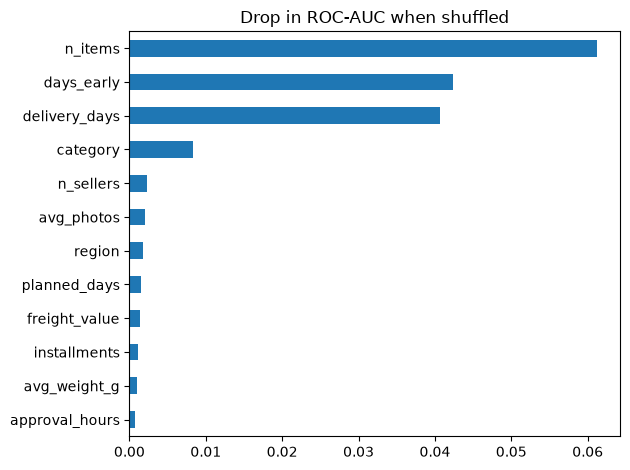

In [12]:
imp.head(12).iloc[::-1].plot.barh(title="Drop in ROC-AUC when shuffled")
plt.tight_layout()
plt.savefig("../reports/figures/04_bad_review_importance.png", dpi=150, bbox_inches="tight")
plt.show()

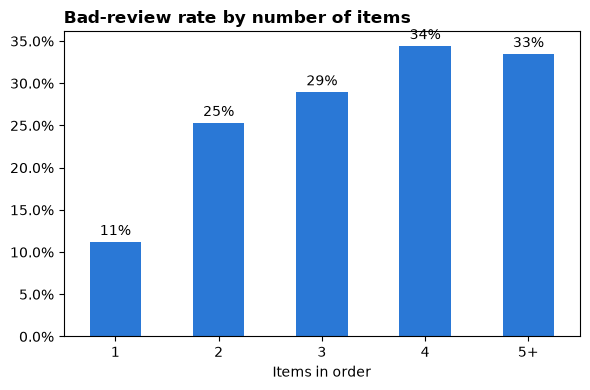

In [ ]:
t = d.groupby(d["n_items"].clip(upper=5))["bad_review"].mean()
t.index = ["1", "2", "3", "4", "5+"]
ax = t.plot.bar(color="#2a78d6", figsize=(6, 4), rot=0)
for i, v in enumerate(t):
    ax.text(i, v + 0.008, f"{v:.0%}", ha="center")
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_xlabel("Items in order")
ax.set_title("Bad-review rate by number of items", loc="left", fontweight="bold")
plt.tight_layout()
plt.savefig("../reports/figures/10_bad_rate_by_items.png", dpi=150, bbox_inches="tight")
plt.show()